# Анализ финансовых результатов строительных предприятий России

**Цель:** на основании финансовых показателей оценить динамику и перспективность строительного направления.

**Данные:** бухгалтерская отчётность ФНС за 2021–2025 гг. Исходная таблица содержит **8 927 юридических лиц** — малые и средние предприятия с основным ОКВЭД **41.20**.

**Рабочая выборка:** первые 500 записей исходного реестра и ещё 500 компаний, случайно выбранных из оставшихся (`random_state=42`).

Notebook работает с готовыми CSV без обращений к API. Код сбора данных вынесен в `Data_Collections_code.ipynb`.

## 1. Подключение библиотек и загрузка данных

In [1]:
from pathlib import Path
import re
from html import escape

import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import folium


In [2]:
DATA_DIR = Path("../datasets")
OUTPUT_DIR = Path("../outputs")

REGISTRY_PATH = DATA_DIR / "Sample_41.20.csv"
COMPANIES_PATH = DATA_DIR / "companies_checkpoint_1000.csv"
FINANCE_PATH = DATA_DIR / "financial_data_v2.csv"
PROFIT_PATH = DATA_DIR / "net_profit_data.csv"
GEOCODE_PATH = DATA_DIR / "geocode_cache.csv"

required = [REGISTRY_PATH, COMPANIES_PATH, FINANCE_PATH, PROFIT_PATH, GEOCODE_PATH]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError("Не найдены файлы в datasets/:\n" + "\n".join(missing))

In [3]:
df = pd.read_csv(REGISTRY_PATH, sep=";", skiprows=2, dtype=str, encoding="utf-8-sig")
df_work = pd.read_csv(COMPANIES_PATH, dtype=str)

print("Реестр:", df.shape)
print("Рабочая выборка:", df_work.shape)
print("Уникальных ИНН:", df_work["ИНН"].nunique())
df_work.head(3)

Реестр: (8927, 20)
Рабочая выборка: (1000, 23)
Уникальных ИНН: 1000


,№ п/п,Наименование / ФИО,Тип субъекта,Категория,ОГРН,ИНН,Основной вид деятельности,Регион,Район,Город,...,Дата исключения из реестра,Наличие лицензий,"Наличие заключенных договоров, контрактов","Производство инновационной, высокотехнологичной продукции",Участие в программах партнерства,Является социальным предприятием,Среднесписочная численность работников за предшествующий календарный год,org_id,parse_status,bfo_status
0,20,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",Юридическое лицо,Малое предприятие,1025004907080,5038038838,41.20 Строительство жилых и нежилых зданий,50 - Московская область,Пушкино г,NaN,...,NaN,Нет,Нет,Нет,Нет,Нет,36,5872486,success,success
1,52,"""ХОЗРАСЧЕТНАЯ СТРОИТЕЛЬНО-ТЕХНОЛОГИЧЕСКАЯ ФИРМ...",Юридическое лицо,Среднее предприятие,1025007270551,5027006369,41.20 Строительство жилых и нежилых зданий,50 - Московская область,NaN,г Дзержинский,...,NaN,Да,Нет,Нет,Нет,Нет,201,6900709,success,success
2,4653,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""777""",Юридическое лицо,Малое предприятие,1021400692048,1414006922,41.20 Строительство жилых и нежилых зданий,77 - г.Москва,NaN,NaN,...,NaN,Да,Нет,Нет,Нет,Нет,35,4980670,success,success


## 2. Подготовка таблицы компаний

Оставляем поля, необходимые для финансового и географического анализа. Пропуски в городе или населённом пункте не удаляем: у некоторых организаций указан только регион регистрации.

In [4]:
company_columns = [
    "ИНН", "Наименование / ФИО", "Категория", "Регион",
    "Район", "Город", "Населенный пункт"
]
df_companies = df_work[company_columns].copy()

print("Дубликатов ИНН:", df_companies["ИНН"].duplicated().sum())
print("Пропуски по столбцам:")
print(df_companies.isna().sum())

Дубликатов ИНН: 0
Пропуски по столбцам:
ИНН                     0
Наименование / ФИО      0
Категория               0
Регион                  0
Район                 860
Город                 382
Населенный пункт      917
dtype: int64


## 3. Финансовые показатели

Из отчётности ФНС используются **выручка**, **чистая прибыль** и **расчётный EBIT**.

В соответствии с методикой задания: **EBIT = прибыль до налогообложения (строка 2300) + проценты к уплате (строка 2330)**. Амортизацию не добавляем.

В `financial_data_v2.csv` уже есть часть значений чистой прибыли. Файл `net_profit_data.csv` содержит дополнительные значения; объединим их **без удаления уже полученных данных**, по ключам `ИНН + год`. Исходные денежные суммы представлены в **тысячах рублей**.

In [5]:
df_finance = pd.read_csv(FINANCE_PATH, dtype={"inn": str})
df_profit = pd.read_csv(PROFIT_PATH, dtype={"inn": str})

for table in (df_finance, df_profit):
    table["year"] = pd.to_numeric(table["year"], errors="raise").astype(int)

df_finance = df_finance.merge(
    df_profit[["inn", "year", "net_profit"]].rename(
        columns={"net_profit": "net_profit_extra"}
    ),
    on=["inn", "year"],
    how="left",
    validate="one_to_one",
)
df_finance["net_profit"] = df_finance["net_profit"].combine_first(
    df_finance["net_profit_extra"]
)
df_finance = df_finance.drop(columns="net_profit_extra")

for column in ["revenue", "profit_before_tax", "interest_expense", "ebit", "net_profit"]:
    df_finance[column] = pd.to_numeric(df_finance[column], errors="coerce")

assert not df_finance.duplicated(["inn", "year"]).any(), "Есть дубликаты ИНН + год"

print("Финансовых записей:", len(df_finance))
print("Компаний с отчётностью:", df_finance["inn"].nunique())
print("Заполненных значений чистой прибыли:", df_finance["net_profit"].count())
df_finance.head(3)

Финансовых записей: 4520
Компаний с отчётностью: 975
Заполненных значений чистой прибыли: 4488


,inn,year,revenue,profit_before_tax,interest_expense,ebit,net_profit
0,5038038838,2023,108966.0,-20665.0,3334.0,-17331.0,-20913.0
1,5038038838,2021,184044.0,3430.0,5601.0,9031.0,3080.0
2,5038038838,2024,112540.0,-19938.0,1521.0,-18417.0,-20129.0


In [6]:
coverage = df_finance.groupby("year").agg(
    companies=("inn", "nunique"),
    net_profit_available=("net_profit", "count"),
    revenue_available=("revenue", "count")
)
coverage

,companies,net_profit_available,revenue_available
year,,,
2021,935,932,927
2022,967,962,953
2023,926,915,894
2024,870,863,844
2025,822,816,790


## 4. Как изменилась чистая прибыль

Сравниваем **2023 и 2025 годы (N = 2)**:

Изменение (%) = ((чистая прибыль 2025 - чистая прибыль 2023)/чистая прибыль 2023) * 100

Для процентного изменения берём компании с **положительной** чистой прибылью в 2023 году и данными за оба года. Переход из убытка в прибыль, нулевую/отрицательную базу учитываем отдельно: процент роста для них неинтерпретируем обычным способом.

In [7]:
profits = df_finance.pivot(index="inn", columns="year", values="net_profit")
paired = profits.dropna(subset=[2023, 2025]).copy()
valid = paired.loc[paired[2023] > 0].copy()

valid["growth_pct"] = (
    100 * (valid[2025] - valid[2023]) / valid[2023]
).round().astype(int)

print("Компаний с прибылью за оба года:", len(paired))
print("С положительной базой для расчёта %:", len(valid))
print("С неположительной базой:", len(paired) - len(valid))

Компаний с прибылью за оба года: 808
С положительной базой для расчёта %: 643
С неположительной базой: 165


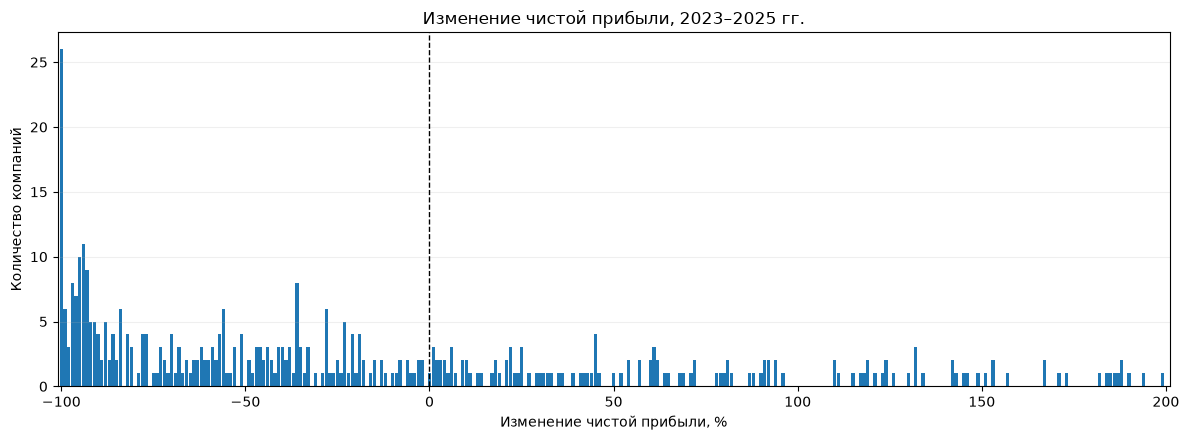

На графике: 410
За диапазоном от −100% до +200%: 233


In [8]:
growth_counts = valid["growth_pct"].value_counts()
visible_counts = growth_counts.reindex(range(-100, 201), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(visible_counts.index, visible_counts.values, width=0.9)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set(title="Изменение чистой прибыли, 2023–2025 гг.",
       xlabel="Изменение чистой прибыли, %", ylabel="Количество компаний")
ax.set_xlim(-101, 201)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print("На графике:", int(visible_counts.sum()))
print("За диапазоном от −100% до +200%:", len(valid) - int(visible_counts.sum()))

График ограничен диапазоном **от −100% до +200%** ради читаемости; экстремальные значения остаются в расчётах, но не показаны на этой оси. Поэтому ниже дополнительно рассмотрим переходы между прибылью и убытком.

In [9]:
profit_to_loss = (paired[2023] > 0) & (paired[2025] < 0)
loss_to_profit = (paired[2023] < 0) & (paired[2025] > 0)
remaining_growth = valid.loc[valid[2025] >= 0, "growth_pct"]

change_groups = pd.Series({
    "Снижение прибыли (−100…−1%)": (remaining_growth < 0).sum(),
    "Около 0% после округления": (remaining_growth == 0).sum(),
    "Рост прибыли (1…200%)": ((remaining_growth > 0) & (remaining_growth <= 200)).sum(),
    "Рост прибыли (>200%)": (remaining_growth > 200).sum(),
    "Из прибыли в убыток": profit_to_loss.sum(),
    "Из убытка в прибыль": loss_to_profit.sum(),
    "Остальные случаи с неположительной базой": ((paired[2023] <= 0) & ~loss_to_profit).sum(),
}).astype(int)

assert change_groups.sum() == len(paired), "Проверь классификацию: компании посчитаны не по одному разу"
change_groups

Снижение прибыли (−100…−1%)                 276
Около 0% после округления                     1
Рост прибыли (1…200%)                       131
Рост прибыли (>200%)                        112
Из прибыли в убыток                         123
Из убытка в прибыль                          63
Остальные случаи с неположительной базой    102
dtype: int64

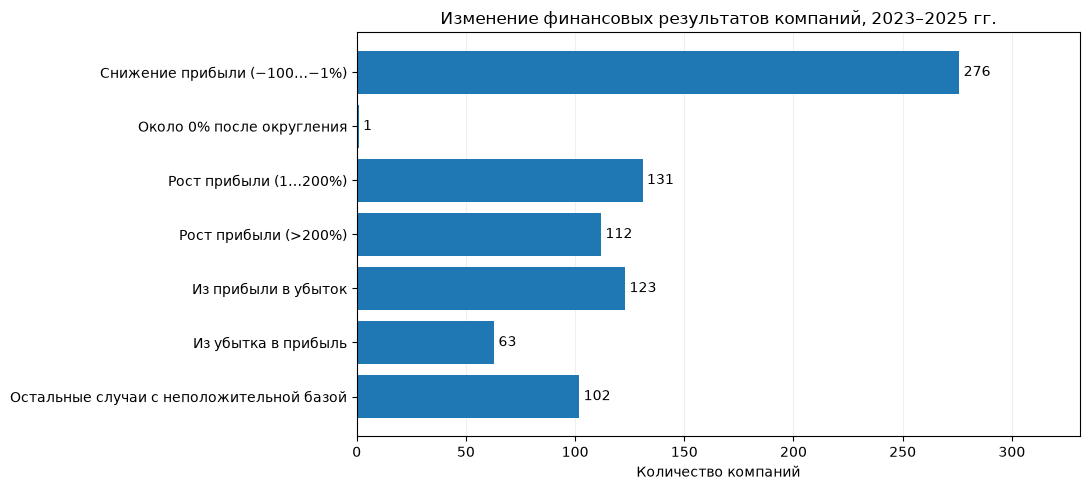

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(change_groups.index, change_groups.values)
ax.bar_label(bars, padding=3)
ax.invert_yaxis()
ax.set(title="Изменение финансовых результатов компаний, 2023–2025 гг.",
       xlabel="Количество компаний", ylabel="")
ax.set_xlim(0, max(change_groups.max() * 1.2, 1))
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [11]:
print(f"Компаний в сравнении: {len(paired)}")
print(f"Из прибыли в убыток: {int(profit_to_loss.sum())}")
print(f"Из убытка в прибыль: {int(loss_to_profit.sum())}")
print(f"Снижение ранее положительной прибыли или переход в убыток: "
      f"{int(change_groups.iloc[0] + profit_to_loss.sum())}")

Компаний в сравнении: 808
Из прибыли в убыток: 123
Из убытка в прибыль: 63
Снижение ранее положительной прибыли или переход в убыток: 399


**Интерпретация.** Для 808 компаний доступны сопоставимые данные о чистой прибыли за 2023 и 2025 годы. У 399 компаний уменьшилась ранее положительная прибыль или возник убыток; 123 компании перешли из прибыли в убыток, а 63 — из убытка в прибыль.

Общую динамику выручки и прибыльности рассмотрим в заключении.

## 5. Топ-500 по выручке и география регистрации

Выбираем **500 компаний с наибольшей выручкой за 2025 год среди исследуемых 1 000**, для которых выручка доступна.

In [12]:
revenue_2025 = df_finance.loc[
    df_finance["year"] == 2025, ["inn", "revenue"]
].dropna(subset=["revenue"]).copy()

assert not revenue_2025["inn"].duplicated().any()
top500 = revenue_2025.nlargest(500, "revenue").copy()
top500_geo = top500.merge(
    df_companies,
    left_on="inn", right_on="ИНН", how="left", validate="one_to_one"
)

print("С выручкой за 2025:", len(revenue_2025))
print("В рейтинге:", len(top500_geo))
print("Без региона:", top500_geo["Регион"].isna().sum())

С выручкой за 2025: 790
В рейтинге: 500
Без региона: 0


### Географические координаты

Используется сохранённый кэш Nominatim. `city_match` означает предварительно найденный населённый пункт, `region_approx` — приблизительное положение региона.

In [13]:
top500_geo["region_clean"] = (
    top500_geo["Регион"].str.replace(r"^\d+\s*-\s*", "", regex=True).str.strip()
)

city_regions = {"77": "Москва", "78": "Санкт-Петербург", "92": "Севастополь"}

def clean_place(value):
    if pd.isna(value):
        return ""
    return re.sub(
        r"^(?:г\.\s*|г\s+|город\s+|с\.\s*|село\s+|п\.\s*|пос\.\s*)",
        "", str(value).strip(), flags=re.IGNORECASE
    ).strip()

def prepare_location(row):
    region_code = str(row["Регион"]).split("-")[0].strip()
    region = row["region_clean"]
    if region_code in city_regions:
        return pd.Series([city_regions[region_code], region, "city"])
    city, settlement = clean_place(row["Город"]), clean_place(row["Населенный пункт"])
    if city:
        return pd.Series([city, region, "city"])
    if settlement:
        return pd.Series([settlement, region, "settlement"])
    return pd.Series(["", region, "region"])

top500_geo[["place", "region_name", "geo_level"]] = top500_geo.apply(
    prepare_location, axis=1
)
top500_geo["geo_key"] = (
    top500_geo["region_name"] + "|" + top500_geo["place"] + "|" + top500_geo["geo_level"]
)

coords = pd.read_csv(GEOCODE_PATH)
top500_mapped = top500_geo.merge(coords, on="geo_key", how="left", validate="many_to_one")
print(top500_mapped["geo_status"].value_counts(dropna=False))

geo_status
city_match       431
needs_review      62
region_approx      7
Name: count, dtype: int64


In [14]:
verified = top500_mapped.loc[
    top500_mapped["geo_status"].isin(["city_match", "region_approx"])
].dropna(subset=["latitude", "longitude"]).copy()

verified["revenue_mln"] = verified["revenue"] / 1000

gdf = gpd.GeoDataFrame(
    verified,
    geometry=gpd.points_from_xy(verified["longitude"], verified["latitude"]),
    crs="EPSG:4326",
)

print(f"На карте: {gdf['inn'].nunique()} из {len(top500_geo)} компаний")
print("Не нанесено (нет или не подтверждены координаты):", len(top500_geo) - gdf["inn"].nunique())

На карте: 438 из 500 компаний
Не нанесено (нет или не подтверждены координаты): 62


In [15]:
# Географические точки уже подготовлены в GeoDataFrame gdf.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if gdf.empty:
    print("Нет подтверждённых координат для построения карты")
else:
    map_data = gdf.copy()
    classes = pd.qcut(map_data["revenue_mln"], q=5, duplicates="drop")
    map_data["revenue_group"] = classes.cat.codes
    colors = ["#fee8a6", "#fccc76", "#f89e55", "#e75a40", "#a50f15"]

    map_view = folium.Map(
        location=[57, 42], zoom_start=4,
        tiles="OpenStreetMap", control_scale=True
    )
    for _, company in map_data.iterrows():
        name = escape(str(company["Наименование / ФИО"]))
        region = escape(str(company["Регион"]))
        revenue = company["revenue_mln"]
        popup = f"<b>{name}</b><br>{region}<br>Выручка: {revenue:,.1f} млн ₽"
        folium.CircleMarker(
            location=[company["latitude"], company["longitude"]],
            radius=5,
            color="#603b30",
            weight=0.6,
            fill=True,
            fill_color=colors[int(company["revenue_group"])],
            fill_opacity=0.8,
            tooltip=f"Выручка: {revenue:,.1f} млн ₽",
            popup=folium.Popup(popup, max_width=320),
        ).add_to(map_view)

    labels = [
        f"{interval.left:,.0f}–{interval.right:,.0f} млн ₽"
        for interval in classes.cat.categories
    ]
    legend_items = "".join(
        f'<div><span style="background:{colors[i]};display:inline-block;width:12px;height:12px;'
        f'border:1px solid #bbb;margin-right:6px"></span>{label}</div>'
        for i, label in enumerate(labels)
    )
    legend = (
        '<div style="position:fixed;bottom:25px;left:25px;z-index:9999;'
        'background:white;padding:10px;border:1px solid #bbb;border-radius:5px;'
        'font-size:12px;line-height:1.8;box-shadow:0 1px 5px #999">'
        '<b>Выручка за 2025 год</b><br>' + legend_items + '</div>'
    )
    map_view.get_root().html.add_child(folium.Element(legend))
    map_view.save(str(OUTPUT_DIR / "top500_registration_map.html"))
    print("Карта сохранена:", OUTPUT_DIR / "top500_registration_map.html")
    display(map_view)

Карта сохранена: ../outputs/top500_registration_map.html


In [16]:
region_stats = (
    top500_geo.groupby("Регион", as_index=False)
    .agg(companies=("inn", "nunique"), total_revenue=("revenue", "sum"))
)
region_stats["revenue_mln"] = region_stats["total_revenue"] / 1000
region_stats = region_stats.sort_values("companies", ascending=False)
region_stats[["Регион", "companies", "revenue_mln"]].head(10)

,Регион,companies,revenue_mln
69,77 - г.Москва,89,80225.073
70,78 - г.Санкт-Петербург,48,36294.967
43,50 - Московская область,40,21305.729
59,66 - Свердловская область,23,17255.583
12,16 - Республика Татарстан (Татарстан),19,13966.304
47,54 - Новосибирская область,18,7261.837
18,23 - Краснодарский край,14,9228.935
56,63 - Самарская область,9,4047.616
19,24 - Красноярский край,9,3982.678
16,21 - Чувашская Республика - Чувашия,9,12271.872


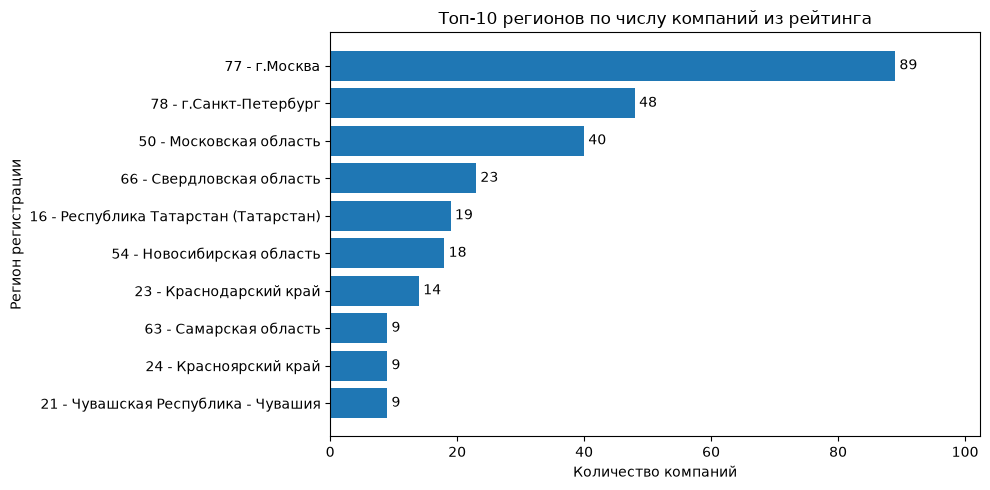

In [17]:
top_regions = region_stats.head(10)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(top_regions["Регион"], top_regions["companies"])
ax.bar_label(bars, padding=3)
ax.invert_yaxis()
ax.set(title="Топ-10 регионов по числу компаний из рейтинга",
       xlabel="Количество компаний", ylabel="Регион регистрации")
ax.set_xlim(0, max(top_regions["companies"].max() * 1.15, 1))
plt.tight_layout()
plt.show()

## 6. Итоговая оценка перспективности

Сравниваем общую выручку и чистую прибыль **одних и тех же компаний**, имеющих оба показателя за 2023 и 2025 годы. Так изменение не будет связано с различным составом компаний в двух годах.

In [18]:
paired_finance = df_finance.loc[
    df_finance["year"].isin([2023, 2025]),
    ["inn", "year", "revenue", "net_profit"]
].pivot(index="inn", columns="year", values=["revenue", "net_profit"])

comparable = paired_finance.dropna(subset=[
    ("revenue", 2023), ("revenue", 2025),
    ("net_profit", 2023), ("net_profit", 2025)
])

financial_summary = pd.DataFrame({
    "Выручка, млрд ₽": [comparable[("revenue", year)].sum() / 1_000_000 for year in (2023, 2025)],
    "Чистая прибыль, млрд ₽": [comparable[("net_profit", year)].sum() / 1_000_000 for year in (2023, 2025)],
}, index=[2023, 2025])
financial_summary["Рентабельность по чистой прибыли, %"] = (
    financial_summary["Чистая прибыль, млрд ₽"] /
    financial_summary["Выручка, млрд ₽"] * 100
)

revenue_change = (
    financial_summary.loc[2025, "Выручка, млрд ₽"] /
    financial_summary.loc[2023, "Выручка, млрд ₽"] - 1
) * 100
profit_change = (
    financial_summary.loc[2025, "Чистая прибыль, млрд ₽"] /
    financial_summary.loc[2023, "Чистая прибыль, млрд ₽"] - 1
) * 100

print("Компаний для сопоставления выручки и чистой прибыли:", len(comparable))
print(f"Изменение выручки: {revenue_change:+.1f}%")
print(f"Изменение чистой прибыли: {profit_change:+.1f}%")
financial_summary.round(2)

Компаний для сопоставления выручки и чистой прибыли: 778
Изменение выручки: +7.5%
Изменение чистой прибыли: -33.0%


,"Выручка, млрд ₽","Чистая прибыль, млрд ₽","Рентабельность по чистой прибыли, %"
2023,307.89,17.40,5.65
2025,330.84,11.67,3.53


### Вывод по строительному направлению

**1. Рост оборотов не привёл к росту прибыли.** По 778 компаниям, у которых есть сопоставимые данные о выручке и чистой прибыли за оба года, совокупная выручка увеличилась **на 7,5%** — примерно с **307,9 до 330,8 млрд ₽**. В то же время суммарная чистая прибыль уменьшилась **на 33,0%** — с **17,4 до 11,7 млрд ₽**. Рентабельность по чистой прибыли снизилась **с 5,65% до 3,53%**. Это означает, что с каждого рубля выручки исследуемые компании в совокупности стали получать меньше чистой прибыли.

**2. Финансовая динамика компаний неоднородна.** Из 808 компаний с данными о чистой прибыли за 2023 и 2025 годы у **399** уменьшилась ранее положительная прибыль или возник убыток. При этом **123 компании** перешли из прибыли в убыток, а **63** — из убытка в прибыль. Часть компаний смогла улучшить финансовый результат, но общая тенденция в сопоставимой группе указывает на снижение прибыльности.

**3. Крупные по выручке компании распределены неравномерно.** Среди 500 организаций с наибольшей выручкой **внутри рабочей выборки** 177 (35,4%) зарегистрированы в Москве, Санкт-Петербурге и Московской области. Регион регистрации не равен месту выполнения строительных работ, поэтому карта показывает распределение юридических лиц, а не строительной активности.

**Оценка перспективности.** По результатам этого исследования строительное направление можно оценить как **умеренно перспективное, но с заметными рисками для прибыльности**. Рост выручки показывает, что у исследуемых компаний сохраняются значительные обороты, однако сокращение прибыли и рентабельности не позволяет сделать однозначно оптимистичный вывод. При оценке конкретной компании важнее смотреть не только на выручку, но и на динамику прибыли и устойчивость финансового результата.

**Ограничения:** вывод относится к учебной выборке малых и средних юридических лиц с основным ОКВЭД 41.20, а не ко всей строительной отрасли России. Выборка частично неслучайная; за отдельные годы есть пропуски в отчётности; показатели представлены в номинальных рублях без поправки на инфляцию. Причины снижения прибыльности по этим данным установить нельзя, а исторические изменения не гарантируют будущую динамику.